# Classification of Optical Glaucoma Detection by using Deep Learning based on Image Processing

# Package Importing

In [5]:
import cv2
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tensorflow.keras.utils import Sequence 
from tensorflow.keras.applications import MobileNet
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import Dense, Dropout, Activation, Flatten, GlobalAveragePooling2D
from tensorflow.keras.layers import Conv2D, ZeroPadding2D, MaxPooling2D
from tensorflow.keras.layers import BatchNormalization
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from keras.callbacks import EarlyStopping,ReduceLROnPlateau #Import callback functions

In [6]:
# pip install tensorflow

In [7]:
# pip install opencv-python

# Datasets Reading

In [8]:
Image_Folder=r'C:\Users\sirfa\Documents\sana\College\PROJECT\DetectionofGlaucoma\Datasets'
Image_Folder

'C:\\Users\\sirfa\\Documents\\sana\\College\\PROJECT\\DetectionofGlaucoma\\Datasets'

# Datasets PreProcessing

In [9]:
batch_size = 32
img_height = 224
img_width = 224

In [10]:
Complete_Image = r'C:\Users\sirfa\Documents\sana\College\PROJECT\DetectionofGlaucoma\Datasets'

In [12]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator
train_datagen = ImageDataGenerator(zoom_range=0.15,width_shift_range=0.2,shear_range=0.15)
test_datagen = ImageDataGenerator()

#Setting train/test split

Train_Image = train_datagen.flow_from_directory(Complete_Image, target_size=(img_height, img_width),
                                                     class_mode="categorical", batch_size=batch_size, subset="training")
Test_Image = test_datagen.flow_from_directory(Complete_Image, target_size=(img_height, img_width),
                                                    class_mode="categorical", batch_size=batch_size, shuffle=False)

Found 184 images belonging to 2 classes.
Found 184 images belonging to 2 classes.


In [13]:
classess = Train_Image.num_classes
classess

2

In [14]:
Test_classess = Test_Image.num_classes
classess

2

# Model Implementation

In [15]:
model = MobileNet(weights='imagenet', include_top = False, input_shape = (224,224,3))

17225924/17225924 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step


In [16]:
for i in model.layers:
    i.trainable = False

In [17]:
def main_model(tl_model,classess):
    m_model = tl_model.output
    m_model = GlobalAveragePooling2D()(m_model)
    m_model = Dense(1024,activation='relu')(m_model)
    m_model = Dense(1024,activation='relu')(m_model)
    m_model = Dense(512,activation='relu')(m_model)
    m_model = Dense(classess,activation = 'softmax')(m_model)
    return m_model

In [18]:
combining_model = main_model(model,classess)

In [19]:
model = Model(inputs=model.input, outputs=combining_model)

In [20]:
model.compile(optimizer="Adam", loss="categorical_crossentropy", metrics=["accuracy"])
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 112, 112, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1_bn (BatchNormalization)   │ (None, 112, 112, 32)   │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1_relu (ReLU)               │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_1 (DepthwiseConv2D)     │ (None, 112, 112, 32)   │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_1_bn                    │ (None, 112, 112, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_1_relu (ReLU)           │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pw_1 (Conv2D)              │ (None, 112, 112, 64)   │         2,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pw_1_bn                    │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pw_1_relu (ReLU)           │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pad_2 (ZeroPadding2D)      │ (None, 113, 113, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_2 (DepthwiseConv2D)     │ (None, 56, 56, 64)     │           576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_2_bn                    │ (None, 56, 56, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_2_relu (ReLU)           │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pw_2 (Conv2D)              │ (None, 56, 56, 128)    │         8,192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pw_2_bn                    │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pw_2_relu (ReLU)           │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_3 (DepthwiseConv2D)     │ (None, 56, 56, 128)    │         1,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_3_bn                    │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_3_relu (ReLU)           │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pw_3 (Conv2D)              │ (None, 56, 56, 128)    │        16,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pw_3_bn                    │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │             

 Total params: 5,853,890 (22.33 MB)

 Trainable params: 2,625,026 (10.01 MB)

 Non-trainable params: 3,228,864 (12.32 MB)

In [21]:
earlystop=EarlyStopping(patience=10) #Monitor the performance. If it dips, then stop training
learning_rate_reduce=ReduceLROnPlateau(monitor="val_accuracy",min_lr=0.001) #Change learning rate if not performing good enough
callbacks=[earlystop,learning_rate_reduce]

In [22]:
history = model.fit(Train_Image, validation_data=Test_Image, epochs=100)

Epoch 1/100


c:\Users\sirfa\anaconda3\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:120: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


6/6 ━━━━━━━━━━━━━━━━━━━━ 18s 2s/step - accuracy: 0.5227 - loss: 1.8762 - val_accuracy: 0.6630 - val_loss: 0.6625
Epoch 2/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 12s 2s/step - accuracy: 0.6225 - loss: 0.6702 - val_accuracy: 0.5000 - val_loss: 0.7473
Epoch 3/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 12s 2s/step - accuracy: 0.5531 - loss: 0.6760 - val_accuracy: 0.5054 - val_loss: 0.6795
Epoch 4/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 12s 2s/step - accuracy: 0.6281 - loss: 0.6335 - val_accuracy: 0.6739 - val_loss: 0.6053
Epoch 5/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 12s 2s/step - accuracy: 0.7503 - loss: 0.5731 - val_accuracy: 0.6630 - val_loss: 0.6006
Epoch 6/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 12s 2s/step - accuracy: 0.7019 - loss: 0.5623 - val_accuracy: 0.6522 - val_loss: 0.5783
Epoch 7/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 12s 2s/step - accuracy: 0.6728 - loss: 0.5977 - val_accuracy: 0.6413 - val_loss: 0.6043
Epoch 8/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 11s 2s/step - accuracy: 0.6330 - loss: 0.6114 - val_accuracy: 0.7065 - val_loss: 0.5413
Epoch 9/100


In [23]:
model.save("my_model2.h5")

In [24]:
Test_score = model.evaluate(Test_Image)
Test_score

6/6 ━━━━━━━━━━━━━━━━━━━━ 5s 764ms/step - accuracy: 0.8563 - loss: 0.3332


[0.28973257541656494, 0.8804348111152649]

# Confusion Matrix of our Model

In [25]:
from sklearn.metrics import classification_report, confusion_matrix
import itertools 


target_names = []
for key in Train_Image.class_indices:
    target_names.append(key)

In [26]:
def plot_confusion_matrix(cm, classes, normalize=False, title='Confusion matrix', cmap=plt.cm.Blues):
    """
    This function prints and plots the confusion matrix.
    Normalization can be applied by setting `normalize=True`.
    """
    
    plt.figure(figsize=(10,10))

    plt.imshow(cm, interpolation='nearest', cmap=cmap)
    plt.title(title)
    plt.colorbar()

    tick_marks = np.arange(len(classes))
    plt.xticks(tick_marks, classes, rotation=45)
    plt.yticks(tick_marks, classes)

    if normalize:
        cm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
        cm = np.around(cm, decimals=2)
        cm[np.isnan(cm)] = 0.0
        print("Normalized confusion matrix")
    else:
        print('Confusion matrix, without normalization')
    thresh = cm.max() / 2.
    for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
        plt.text(j, i, cm[i, j],
                 horizontalalignment="center",
                 color="white" if cm[i, j] > thresh else "black")
    plt.tight_layout()
    plt.ylabel('True label')
    plt.xlabel('Predicted label')

6/6 ━━━━━━━━━━━━━━━━━━━━ 6s 893ms/step
Confusion Matrix
Confusion matrix, without normalization


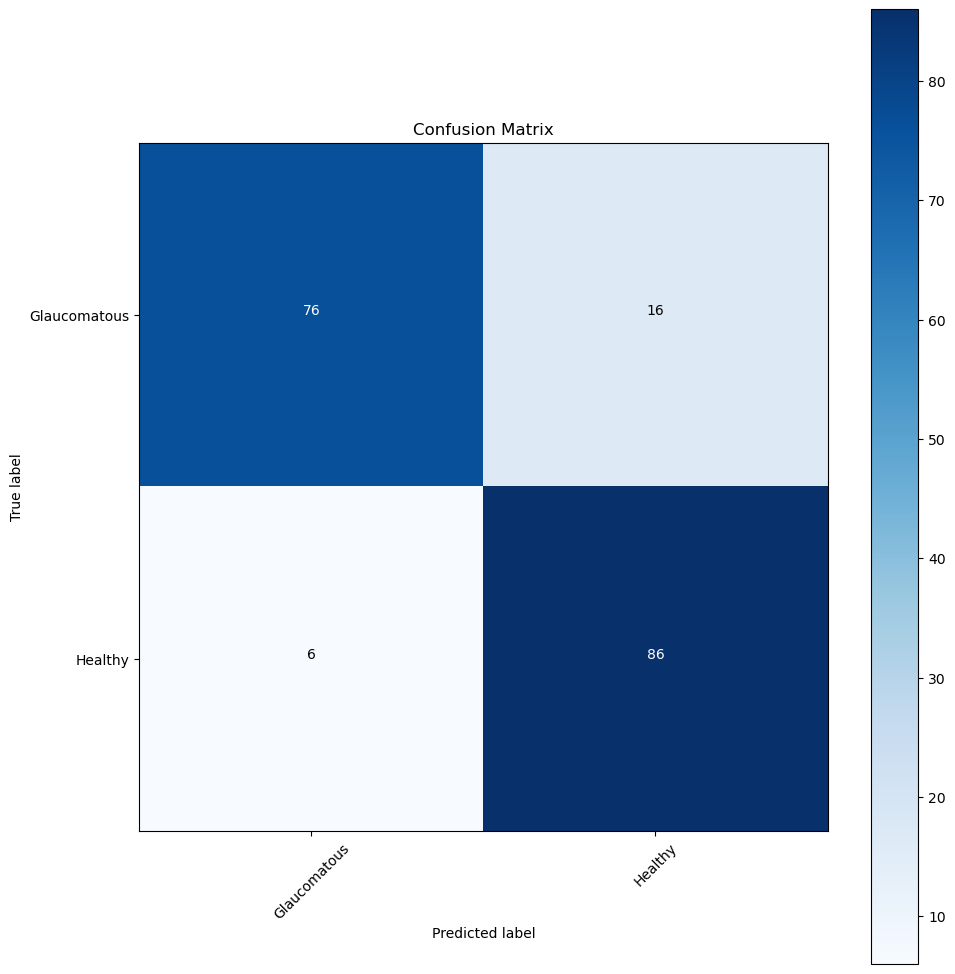

In [27]:
#Confution Matrix and Classification Report
Y_pred_Model = model.predict(Test_Image)
Y_pred_Model = np.argmax(Y_pred_Model, axis=-1)
print('Confusion Matrix') 
CM_Model=confusion_matrix(Test_Image.classes, Y_pred_Model)

plot_confusion_matrix(CM_Model, target_names, title='Confusion Matrix')


# Classification Report

In [28]:
print('Classification Report')
print(classification_report(Test_Image.classes, Y_pred_Model, target_names=target_names))

Classification Report
              precision    recall  f1-score   support

Glaucomatous       0.93      0.83      0.87        92
     Healthy       0.84      0.93      0.89        92

    accuracy                           0.88       184
   macro avg       0.88      0.88      0.88       184
weighted avg       0.88      0.88      0.88       184



# Plotting Accuracy and Loss 

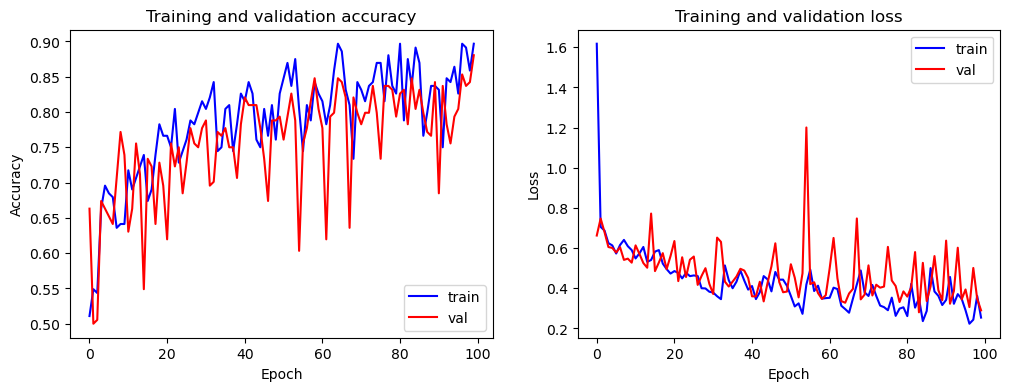

In [29]:
Train_accuracy = history.history['accuracy']
Val_accuracy = history.history['val_accuracy']
Train_loss = history.history['loss']
Val_loss = history.history['val_loss']

epochs = range(len(Train_accuracy))
plt.figure(figsize=(12,4))

# Plotting the accuracy
plt.subplot(1,2,1)
plt.plot(epochs, Train_accuracy, 'b', label='Training accuracy')
plt.plot(epochs, Val_accuracy, 'r', label='Validation accuracy')
plt.title('Training and validation accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(['train', 'val'], loc='lower right')

# Plotting the loss
plt.subplot(1,2,2)
plt.plot(epochs, Train_loss, 'b', label='Training loss')
plt.plot(epochs, Val_loss, 'r', label='Validation loss')
plt.title('Training and validation loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(['train', 'val'], loc='upper right')

plt.show()

# Testing the Image

In [30]:
labels = Train_Image.class_indices
final_labels = {v: k for k, v in labels.items()}
final_labels

{0: 'Glaucomatous', 1: 'Healthy'}

In [31]:
from tensorflow.keras.models import load_model
import ast
from tensorflow.keras.preprocessing import image

In [32]:
def predict_image(imgname, from_test_dir):
    test_image = image.load_img(imgname, target_size = (224, 224))

    plt.imshow(test_image)
    plt.show()

    test_image = np.asarray(test_image)
    test_image = np.expand_dims(test_image, axis=0)
    result = model.predict(test_image)

    result_dict = dict()
    for key in list(final_labels.keys()):
        result_dict[final_labels[key]] = result[0][key]
    sorted_results = {k: v for k, v in sorted(result_dict.items(), key=lambda item: item[1], reverse=True)}

    if not from_test_dir:
        print('=' * 50)
        for label in sorted_results.keys():
            print("{}: {}%".format(label, sorted_results[label] * 100))

    final_result = dict()
    final_result[list(sorted_results.keys())[0]] = sorted_results[list(sorted_results.keys())[0]] * 100

    return final_result




# Testing Image : Normal Eye Image

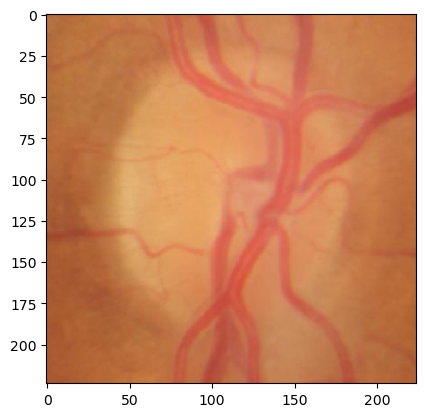

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
Healthy: 66.51771068572998%
Glaucomatous: 33.48229229450226%
Final Result:  {'Healthy': 66.51771068572998}


In [33]:
FinalImage_Normal = predict_image(r"C:\Users\sirfa\Documents\sana\College\PROJECT\DetectionofGlaucoma\Datasets\Healthy\normal_23.jpg", False)
print("Final Result: ", FinalImage_Normal)

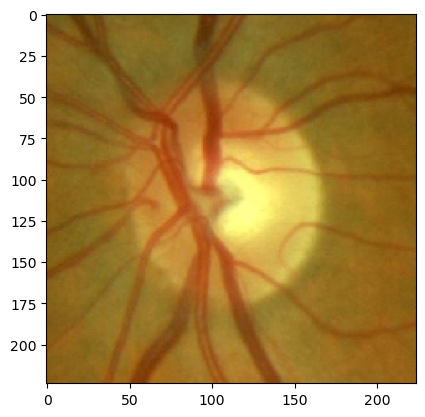

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 98ms/step
Healthy: 99.9993085861206%
Glaucomatous: 0.0006957271580176894%
Final Result:  {'Healthy': 99.9993085861206}


In [34]:
FinalImage_Normal = predict_image(r"C:\Users\sirfa\Documents\sana\College\PROJECT\DetectionofGlaucoma\Datasets\Healthy\normal_550.jpg", False)
print("Final Result: ", FinalImage_Normal)

# Testing Image : Glaucoma Image

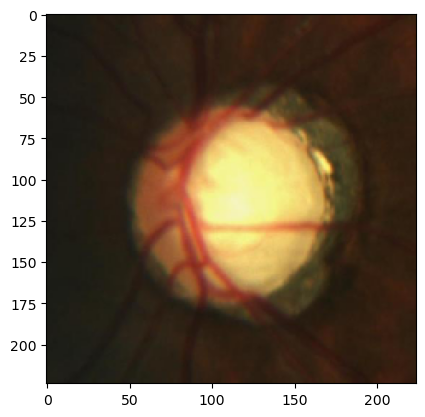

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step
Glaucomatous: 99.80363249778748%
Healthy: 0.19636349752545357%
Final Result:  {'Glaucomatous': 99.80363249778748}


In [35]:
FinalImage_glaucoma = predict_image(r"C:\Users\sirfa\Documents\sana\College\PROJECT\DetectionofGlaucoma\Datasets\Glaucomatous\glaucoma_26.jpg", False)
print("Final Result: ", FinalImage_glaucoma)

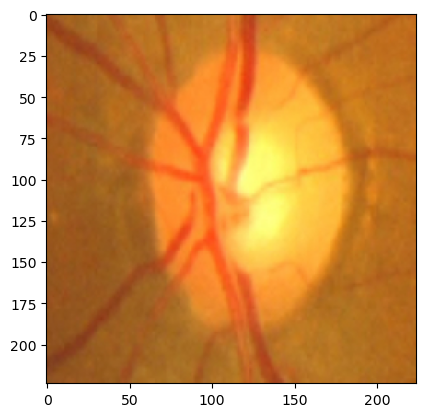

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step
Glaucomatous: 78.69658470153809%
Healthy: 21.303415298461914%
Final Result:  {'Glaucomatous': 78.69658470153809}


In [36]:
FinalImage_glaucoma = predict_image(r"C:\Users\sirfa\Documents\sana\College\PROJECT\DetectionofGlaucoma\Datasets\Glaucomatous\glaucoma_804.jpg", False)
print("Final Result: ", FinalImage_glaucoma)